# Session-Adaptive Threshold Analysis

This notebook loads logged session-adaptive threshold statistics and plots how threshold adaptation changes across sessions and over training.

In [29]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['figure.figsize'] = (12, 6)

## Configure Input

Point `LOG_PATH` to either a `.csv` file or a `.jsonl` file containing:

- `session_id`
- `batch`
- `delta_v_th_mean`
- `delta_v_th_std`

In [ ]:
LOG_PATH = Path('../logs/snn/2026-04-07_22-36-37_374330_snn_pid1490016/spiking_stats/session_threshold_adapter.jsonl')

required_columns = [
    'session_id',
    'batch',
    'delta_v_th_mean',
    'delta_v_th_std',
]

In [31]:
def load_threshold_stats(path: Path) -> pd.DataFrame:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File not found: {path}')

    if path.suffix.lower() == '.csv':
        df = pd.read_csv(path)
    elif path.suffix.lower() in {'.jsonl', '.ndjson'}:
        rows = []
        with path.open('r') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                row = json.loads(line)
                if row.get('session_id') is None:
                    continue
                rows.append(row)
        df = pd.DataFrame(rows)
    else:
        raise ValueError(f'Unsupported file type: {path.suffix}')
    
    print(df['epoch'].unique())
    missing = [col for col in required_columns if col not in df.columns]
    if missing:
        raise ValueError(f'Missing required columns: {missing}')
    
    df = df[required_columns].copy()
    df['session_id'] = df['session_id'].astype(int)
    df['batch'] = df['batch'].astype(int)
    df['delta_v_th_mean'] = pd.to_numeric(df['delta_v_th_mean'])
    df['delta_v_th_std'] = pd.to_numeric(df['delta_v_th_std'])
    df = df.sort_values(['session_id', 'batch']).reset_index(drop=True)
    return df


df = load_threshold_stats(LOG_PATH)

print(f'Loaded {len(df)} rows from {LOG_PATH}')
print(f'Standard deviation of delta_v_th: {df["delta_v_th_std"].unique()}')
print(f'Mean of delta_v_th: {df["delta_v_th_mean"].unique()}')
display(df.head())

[0]
Loaded 360000 rows from ../logs/snn/2026-04-07_22-07-06_947628_snn_pid1482545/spiking_stats/session_threshold_adapter.jsonl
Standard deviation of delta_v_th: [0.00760647 0.00760644 0.00760642 ... 0.01242382 0.01242372 0.01242354]
Mean of delta_v_th: [0.00043248 0.00043247 0.00043246 ... 0.00123657 0.00123663 0.00123675]


,session_id,batch,delta_v_th_mean,delta_v_th_std
0,0,0,0.000432,0.007606
1,0,1,0.000432,0.007606
2,0,2,0.000432,0.007606
3,0,3,0.000432,0.007606
4,0,4,0.000432,0.007606


## Basic Overview

In [32]:
print('Sessions:', df['session_id'].nunique())
print('Logged batches:', df['batch'].nunique())
print('Batch range:', (df['batch'].min(), df['batch'].max()))
display(df.groupby('session_id').size().rename('num_rows').to_frame().head(10))

Sessions: 45
Logged batches: 8000
Batch range: (0, 7999)


,num_rows
session_id,
0,8000
1,8000
2,8000
3,8000
4,8000
5,8000
6,8000
7,8000
8,8000


## Per-Session Plots

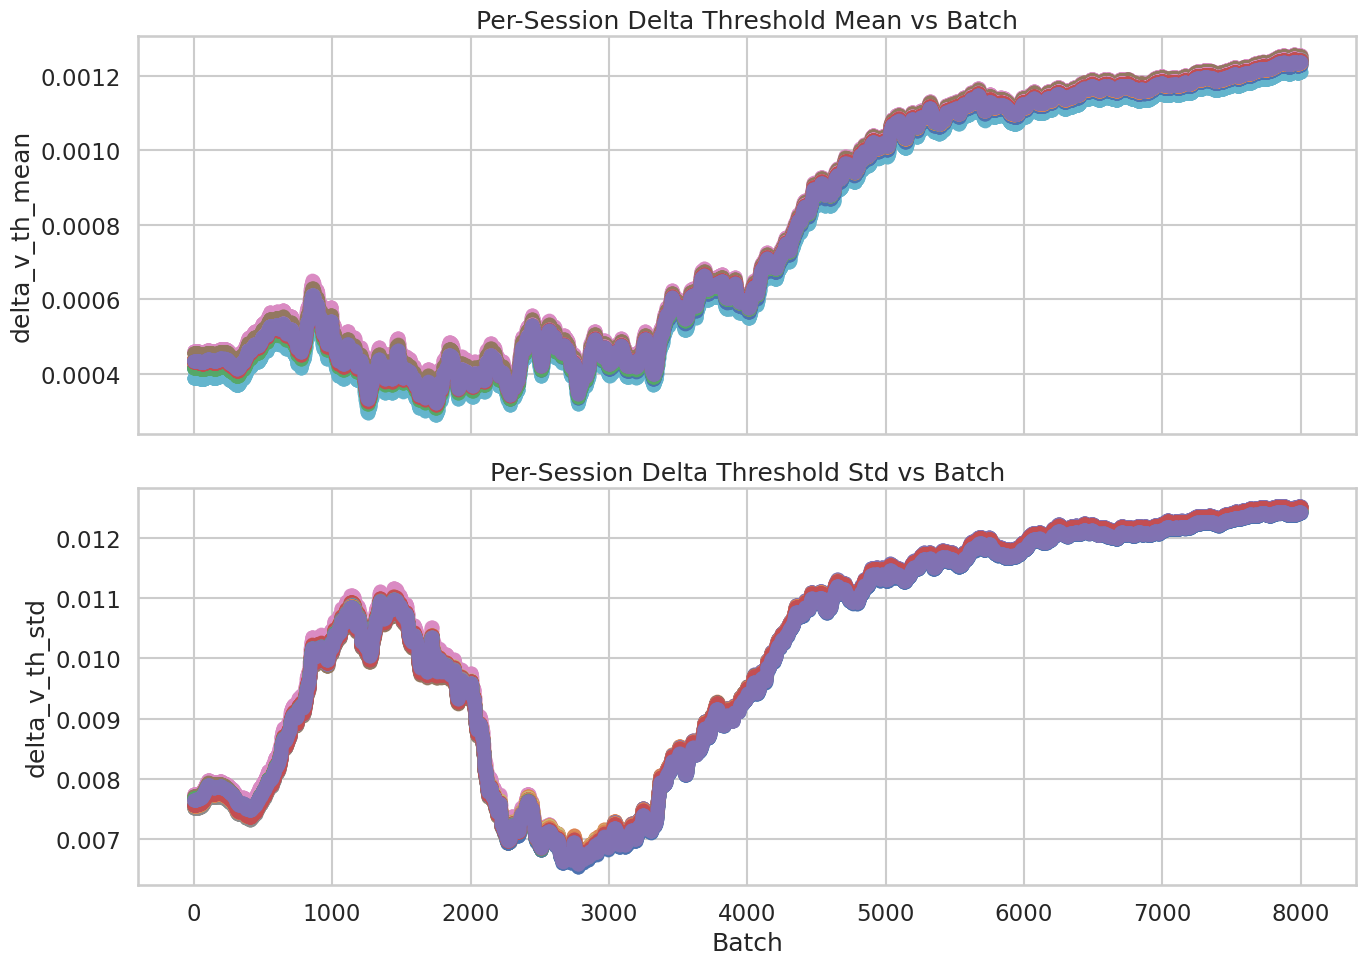

In [33]:
session_ids = sorted(df['session_id'].unique())

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
for session_id in session_ids:
    session_df = df[df['session_id'] == session_id]
    axes[0].plot(session_df['batch'], session_df['delta_v_th_mean'], marker='o', linewidth=2, alpha=0.8, label=f'session {session_id}')
    axes[1].plot(session_df['batch'], session_df['delta_v_th_std'], marker='o', linewidth=2, alpha=0.8, label=f'session {session_id}')

axes[0].set_title('Per-Session Delta Threshold Mean vs Batch')
axes[0].set_ylabel('delta_v_th_mean')
axes[1].set_title('Per-Session Delta Threshold Std vs Batch')
axes[1].set_xlabel('Batch')
axes[1].set_ylabel('delta_v_th_std')

if len(session_ids) <= 12:
    axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

## Compare All Sessions Together

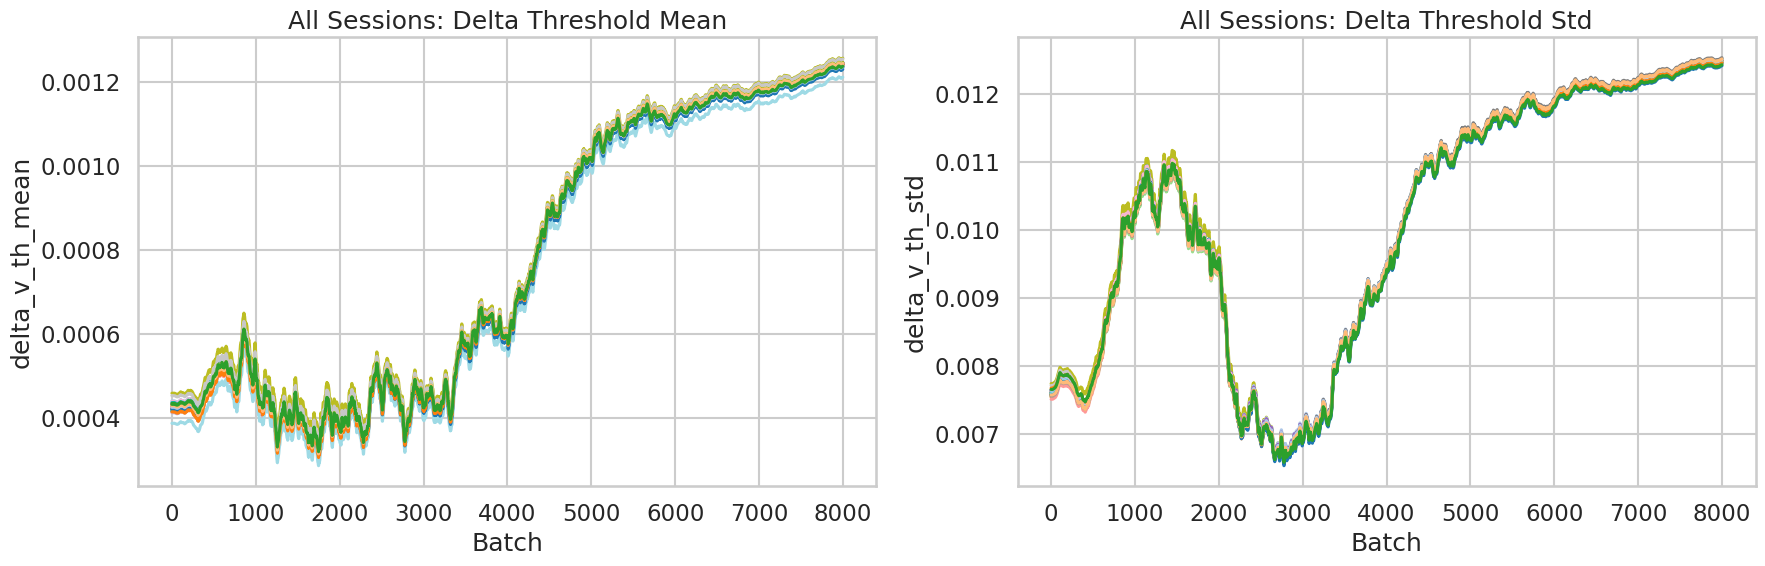

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharex=True)

sns.lineplot(data=df, x='batch', y='delta_v_th_mean', hue='session_id', palette='tab20', legend=False, ax=axes[0])
sns.lineplot(data=df, x='batch', y='delta_v_th_std', hue='session_id', palette='tab20', legend=False, ax=axes[1])

axes[0].set_title('All Sessions: Delta Threshold Mean')
axes[0].set_xlabel('Batch')
axes[0].set_ylabel('delta_v_th_mean')
axes[1].set_title('All Sessions: Delta Threshold Std')
axes[1].set_xlabel('Batch')
axes[1].set_ylabel('delta_v_th_std')

plt.tight_layout()
plt.show()

## Across-Session Summary Per Logged Batch

In [35]:
batch_summary = (
    df.groupby('batch')['delta_v_th_mean']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .rename(columns={'mean': 'mean_across_sessions', 'std': 'std_across_sessions'})
)
print(batch_summary['mean_across_sessions'].unique())
print(batch_summary['std_across_sessions'].unique())
display(batch_summary)

[0.00042821 0.0004282  0.00042819 ... 0.00124001 0.00124007 0.0012402 ]
[1.06955778e-05 1.06956129e-05 1.06956444e-05 ... 6.47208323e-06
 6.47214991e-06 6.47221090e-06]


,batch,mean_across_sessions,std_across_sessions,count
0,0,0.000428,0.000011,45
1,1,0.000428,0.000011,45
2,2,0.000428,0.000011,45
3,3,0.000428,0.000011,45
4,4,0.000428,0.000011,45
...,...,...,...,...
7995,7995,0.001240,0.000006,45
7996,7996,0.001240,0.000006,45
7997,7997,0.001240,0.000006,45
7998,7998,0.001240,0.000006,45


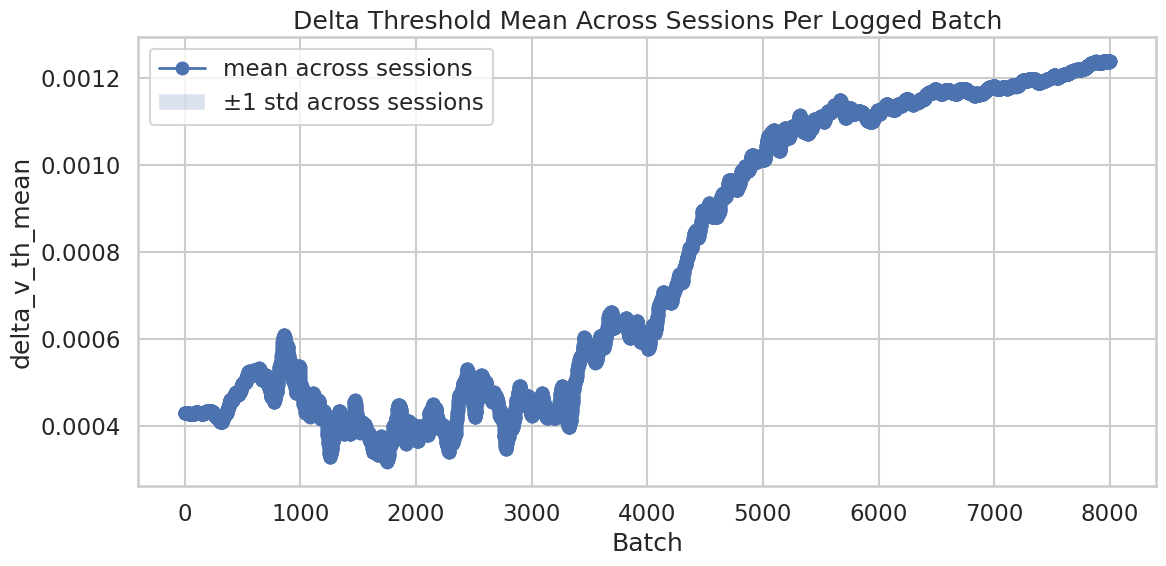

In [36]:
plt.figure(figsize=(12, 6))
plt.plot(batch_summary['batch'], batch_summary['mean_across_sessions'], marker='o', linewidth=2, label='mean across sessions')
plt.fill_between(
    batch_summary['batch'],
    batch_summary['mean_across_sessions'] - batch_summary['std_across_sessions'].fillna(0),
    batch_summary['mean_across_sessions'] + batch_summary['std_across_sessions'].fillna(0),
    alpha=0.2,
    label='±1 std across sessions',
)
plt.title('Delta Threshold Mean Across Sessions Per Logged Batch')
plt.xlabel('Batch')
plt.ylabel('delta_v_th_mean')
plt.legend()
plt.tight_layout()
plt.show()

## Variability at the Last Epoch

In [37]:
last_batch = df['batch'].max()
last_batch_df = df[df['batch'] == last_batch].copy()

print(f'Last logged batch: {last_batch}')
display(last_batch_df.sort_values('delta_v_th_mean'))

Last logged batch: 7999


,session_id,batch,delta_v_th_mean,delta_v_th_std
319999,39,7999,0.001211,0.012438
327999,40,7999,0.001230,0.012409
239999,29,7999,0.001233,0.012449
311999,38,7999,0.001235,0.012448
279999,34,7999,0.001235,0.012526
335999,41,7999,0.001235,0.012498
71999,8,7999,0.001236,0.012460
159999,19,7999,0.001236,0.012457
359999,44,7999,0.001237,0.012424
167999,20,7999,0.001238,0.012486


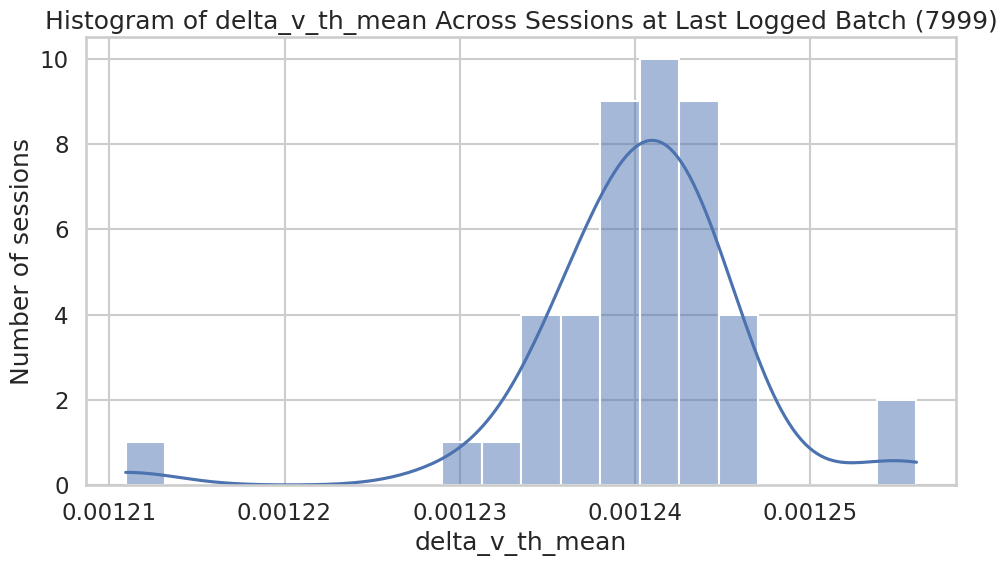

In [38]:
plt.figure(figsize=(10, 6))
sns.histplot(last_batch_df['delta_v_th_mean'], bins=20, kde=True)
plt.title(f'Histogram of delta_v_th_mean Across Sessions at Last Logged Batch ({last_batch})')
plt.xlabel('delta_v_th_mean')
plt.ylabel('Number of sessions')
plt.tight_layout()
plt.show()

## Quick Debugging Notes

Things to look for:

- Do different sessions converge to noticeably different `delta_v_th_mean` values?
- Does `delta_v_th_std` shrink, stabilize, or keep drifting over logged batches?
- Does the across-session standard deviation shrink over time?
- At the last logged batch, is the histogram narrow and centered, or broad and session-specific?